In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

def plot_operating_curve(alpha=1.0):
    utiliz = np.linspace(0.01, 0.99, 200)
    FF = alpha * utiliz / (1 - utiliz) + 1

    plt.figure(figsize=(8,6))
    plt.plot(utiliz * 100, FF, label=f'Alpha = {alpha:.2f}')
    plt.xlabel('Utilization [%]')
    plt.ylabel('Flow Factor (FF)')
    plt.title('Operating Curve (Flow Factor vs Utilization)')
    plt.grid(True)
    plt.legend()
    plt.ylim(bottom=1)
    plt.show()

interact(plot_operating_curve, alpha=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1))


interactive(children=(FloatSlider(value=1.0, description='alpha', max=5.0, min=0.1), Output()), _dom_classes=(…

<function __main__.plot_operating_curve(alpha=1.0)>

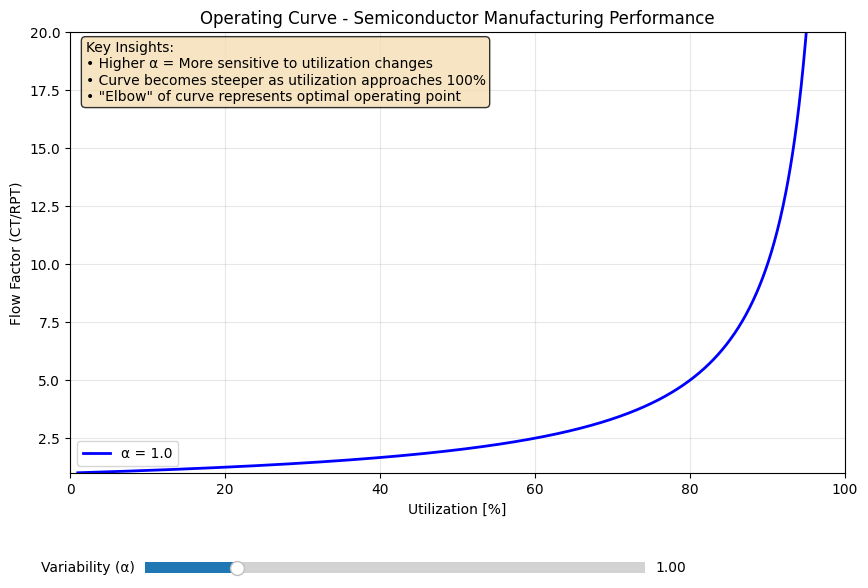

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

def plot_operating_curve():
    # Create figure and axis
    fig, ax = plt.subplots(figsize=(10, 7))
    plt.subplots_adjust(bottom=0.25)

    # Define initial parameters
    initial_alpha = 1.0  # Initial variability coefficient
    utilization = np.linspace(0.01, 0.95, 1000)  # Utilization from 1% to 95%
    RPT = 1  # Raw Process Time (normalized to 1 for simplicity)

    # Calculate Flow Factor based on formula (2.9): FF = α * utiliz / (1 - utiliz) + 1
    def calculate_flow_factor(alpha, util):
        return alpha * util / (1 - util) + 1

    # Initial flow factor calculation
    flow_factor = calculate_flow_factor(initial_alpha, utilization)

    # Plot initial curve
    line, = ax.plot(utilization * 100, flow_factor, 'b-', linewidth=2, label=f'α = {initial_alpha}')
    ax.set_xlabel('Utilization [%]')
    ax.set_ylabel('Flow Factor (CT/RPT)')
    ax.set_title('Operating Curve - Semiconductor Manufacturing Performance')
    ax.grid(True, alpha=0.3)
    ax.legend()

    # Set axis limits
    ax.set_xlim([0, 100])
    ax.set_ylim([1, 20])

    # Create slider axes
    ax_slider = plt.axes([0.2, 0.1, 0.5, 0.03])

    # Create slider
    slider_alpha = Slider(
        ax_slider,
        'Variability (α)',
        0.1,
        5.0,
        valinit=initial_alpha,
        valfmt='%.2f'
    )

    def update(val):
        alpha = slider_alpha.val
        flow_factor = calculate_flow_factor(alpha, utilization)
        line.set_ydata(flow_factor)
        line.set_label(f'α = {alpha:.2f}')
        ax.legend()
        fig.canvas.draw_idle()

    slider_alpha.on_changed(update)

    # Add text explaining the curve behavior
    ax.text(0.02, 0.98, 'Key Insights:\n• Higher α = More sensitive to utilization changes\n• Curve becomes steeper as utilization approaches 100%\n• "Elbow" of curve represents optimal operating point',
            transform=ax.transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    plt.show()

# Run the function
plot_operating_curve()

In [3]:
# First, install and enable ipywidgets (usually pre-installed in Colab, but safe to run)
!pip install -q ipywidgets
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider
import warnings
warnings.filterwarnings("ignore")

# Define utilization range and flow factor function
utilization = np.linspace(0.01, 0.95, 500)

def flow_factor(alpha, u):
    return alpha * u / (1 - u) + 1

# Interactive plotting function
def plot_operating_curve(alpha=1.0):
    plt.figure(figsize=(10, 6))
    ff = flow_factor(alpha, utilization)
    plt.plot(utilization * 100, ff, 'b-', lw=2.5, label=f'α = {alpha:.2f}')

    plt.xlabel('Utilization [%]')
    plt.ylabel('Flow Factor (CT / RPT)')
    plt.title('Operating Curve – Semiconductor Manufacturing')
    plt.grid(True, alpha=0.3)
    plt.xlim(0, 100)
    plt.ylim(1, 20)
    plt.legend()

    # Add explanatory text
    plt.text(5, 18, f'Higher α → More variability → Steeper curve\nLow α (e.g., {0.3:.1f}) = mature, stable fab',
             bbox=dict(boxstyle="round,pad=0.3", facecolor="wheat", alpha=0.8))

    plt.show()

# Create interactive widget
interact(
    plot_operating_curve,
    alpha=FloatSlider(value=1.0, min=0.1, max=2.0, step=0.1, description='Variability (α):')
);

interactive(children=(FloatSlider(value=1.0, description='Variability (α):', max=2.0, min=0.1), Output()), _do…

In [4]:
!pip install -q ipywidgets
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, Output, VBox, HTML
import warnings
warnings.filterwarnings("ignore")

# Define utilization range
utilization = np.linspace(0.01, 0.95, 500)

def flow_factor(alpha, u):
    return alpha * u / (1 - u) + 1

# Function to interpret alpha
def interpret_alpha(alpha):
    if alpha < 0.5:
        return "<b>Very Low Variability (α < 0.5)</b><br>✔️ Highly mature fab<br>✔️ Stable processes<br>✔️ Predictable cycle times<br>✔️ Minimal disruptions (failures, setups, rework)"
    elif alpha < 1.0:
        return "<b>Low Variability (0.5 ≤ α < 1.0)</b><br>✅ Well-controlled operations<br>✅ Occasional minor disruptions<br>✅ Good balance of utilization & speed"
    elif alpha < 2.0:
        return "<b>Moderate Variability (1.0 ≤ α < 2.0)</b><br>⚠️ Noticeable sensitivity to utilization<br>⚠️ Machine failures or setups affect flow<br>⚠️ Cycle time grows quickly near high utilization"
    elif alpha < 3.5:
        return "<b>High Variability (2.0 ≤ α < 3.5)</b><br>❌ Unstable production line<br>❌ Frequent disruptions (downtime, rework)<br>❌ Poor schedule adherence<br>❌ CT explodes even at medium utilization"
    else:
        return "<b>Very High Variability (α ≥ 3.5)</b><br>🔥 Highly chaotic fab<br>🔥 Unreliable delivery performance<br>🔥 Not advisable to operate above ~60% utilization"

# Main interactive function
def plot_with_interpretation(alpha=1.0):
    ff = flow_factor(alpha, utilization)

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.plot(utilization * 100, ff, 'b-', lw=2.5, label=f'α = {alpha:.2f}')
    ax.set_xlabel('Utilization [%]')
    ax.set_ylabel('Flow Factor (CT / RPT)')
    ax.set_title('Operating Curve – Semiconductor Manufacturing')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 100)
    ax.set_ylim(1, 20)
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Display interpretation
    interpretation_html.value = (
        f"<div style='padding: 10px; margin-top: 10px; "
        f"background-color: #f0f8ff; border-left: 4px solid #1e88e5; font-family: Arial;'>"
        f"<b>Interpretation of α = {alpha:.2f}:</b><br>"
        f"{interpret_alpha(alpha)}"
        f"</div>"
    )

# Create HTML widget for dynamic text
interpretation_html = HTML(value="")

# Create slider and link to function
slider = FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, description='Variability (α):')

# Use interact with VBox to show plot + text
ui = VBox([slider, interpretation_html])
out = Output()

def on_value_change(change):
    with out:
        out.clear_output(wait=True)
        plot_with_interpretation(change['new'])

slider.observe(on_value_change, names='value')
display(ui, out)

# Trigger initial plot
on_value_change({'new': slider.value})

Output()